In [1]:
!pip -q install pandas polars openpyxl psutil matplotlib

In [16]:
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import requests
import zipfile
import io
import os
import time
import gc
import psutil

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = requests.get(url, timeout=120)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    excel_name = next(
        name for name in archive.namelist()
        if name.lower().endswith(".xlsx")
    )
    with archive.open(excel_name) as file:
        raw_df = pd.read_excel(file, nrows=150_000)

# Save a common CSV for both libraries
csv_path = "/content/online_retail_sample.csv"
raw_df.to_csv(csv_path, index=False)

print("Dataset prepared successfully!")
print("Rows:", len(raw_df))
print("Columns:", len(raw_df.columns))
print("File size:", round(os.path.getsize(csv_path) / (1024**2), 2), "MB")

display(raw_df.head())

Dataset prepared successfully!
Rows: 150000
Columns: 8
File size: 12.62 MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


###Loading the dataset

In [4]:
# PANDAS
start = time.perf_counter()
pandas_df = pd.read_csv(csv_path, parse_dates=["InvoiceDate"])
pandas_load_time = time.perf_counter() - start

# POLARS
start = time.perf_counter()
polars_df = pl.read_csv(csv_path, try_parse_dates=True, schema_overrides={"InvoiceNo": pl.String})
polars_load_time = time.perf_counter() - start

# SIDE-BY-SIDE COMPARISON
load_results = pd.DataFrame({
    "Library": ["Pandas", "Polars"],
    "Rows": [pandas_df.shape[0], polars_df.height],
    "Columns": [pandas_df.shape[1], polars_df.width],
    "Load Time (seconds)": [pandas_load_time, polars_load_time]
})

display(load_results)

,Library,Rows,Columns,Load Time (seconds)
0,Pandas,150000,8,0.208147
1,Polars,150000,8,0.086913


###Filter rows

In [5]:
# PANDAS
start = time.perf_counter()

pandas_filtered = pandas_df[
    (pandas_df["Quantity"] > 0) &
    (pandas_df["UnitPrice"] > 0)
].copy()

pandas_filter_time = time.perf_counter() - start

# POLARS
start = time.perf_counter()

polars_filtered = polars_df.filter(
    (pl.col("Quantity") > 0) &
    (pl.col("UnitPrice") > 0)
)

polars_filter_time = time.perf_counter() - start

# COMPARE
filter_results = pd.DataFrame({
    "Library": ["Pandas", "Polars"],
    "Filtered Rows": [
        len(pandas_filtered),
        polars_filtered.height
    ],
    "Execution Time (seconds)": [
        pandas_filter_time,
        polars_filter_time
    ]
})

display(filter_results)

,Library,Filtered Rows,Execution Time (seconds)
0,Pandas,146355,0.020526
1,Polars,146355,0.095714


###Select columns

In [6]:
columns = [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "UnitPrice", "Country"
]

# PANDAS
start = time.perf_counter()
pandas_selected = pandas_filtered[columns].copy()
pandas_select_time = time.perf_counter() - start

# POLARS
start = time.perf_counter()
polars_selected = polars_filtered.select(columns)
polars_select_time = time.perf_counter() - start

# COMPARE
select_results = pd.DataFrame({
    "Library": ["Pandas", "Polars"],
    "Rows": [len(pandas_selected), polars_selected.height],
    "Columns": [len(pandas_selected.columns), polars_selected.width],
    "Execution Time (seconds)": [
        pandas_select_time, polars_select_time
    ]
})

display(select_results)

,Library,Rows,Columns,Execution Time (seconds)
0,Pandas,146355,6,0.017822
1,Polars,146355,6,0.001350


###Group and aggregate

In [7]:
# PANDAS
start = time.perf_counter()

pandas_selected["Revenue"] = (
    pandas_selected["Quantity"] *
    pandas_selected["UnitPrice"]
)

pandas_grouped = (
    pandas_selected.groupby("StockCode", as_index=False)
    .agg(
        Quantity=("Quantity", "sum"),
        Revenue=("Revenue", "sum"),
        Invoices=("InvoiceNo", "nunique")
    )
)

pandas_group_time = time.perf_counter() - start

# POLARS
start = time.perf_counter()

polars_selected = polars_selected.with_columns(
    (pl.col("Quantity") * pl.col("UnitPrice")).alias("Revenue")
)

polars_grouped = (
    polars_selected.group_by("StockCode")
    .agg(
        pl.col("Quantity").sum(),
        pl.col("Revenue").sum(),
        pl.col("InvoiceNo").n_unique().alias("Invoices")
    )
)

polars_group_time = time.perf_counter() - start

# COMPARE
group_results = pd.DataFrame({
    "Library": ["Pandas", "Polars"],
    "Grouped Products": [
        len(pandas_grouped), polars_grouped.height
    ],
    "Execution Time (seconds)": [
        pandas_group_time, polars_group_time
    ]
})

display(group_results)

print("Pandas grouped results:")
display(pandas_grouped.head())

print("Polars grouped results:")
display(polars_grouped.head())

,Library,Grouped Products,Execution Time (seconds)
0,Pandas,3195,0.078141
1,Polars,3195,0.062421


Pandas grouped results:


,StockCode,Quantity,Revenue,Invoices
0,10002,797,706.34,69
1,10080,2,1.70,1
2,10120,75,15.75,9
3,10123C,5,3.25,3
4,10124A,12,5.04,4


Polars grouped results:


StockCode,Quantity,Revenue,Invoices
str,i64,f64,u32
"""82613b""",2,5.02,2
"""22470""",3660,11282.84,337
"""84406B""",1052,3770.06,153
"""90059B""",6,10.02,5
"""22548""",411,610.61,68


###join datasets

In [8]:
# Prepare the same lookup data for both libraries
products_pd = (
    pandas_df[["StockCode", "Description"]]
    .dropna(subset=["StockCode"])
    .drop_duplicates(subset=["StockCode"])
    .copy()
)

products_pl = (
    polars_df.select(["StockCode", "Description"])
    .filter(pl.col("StockCode").is_not_null())
    .unique(subset=["StockCode"], keep="first")
)

# PANDAS
start = time.perf_counter()

pandas_joined = pandas_grouped.merge(
    products_pd,
    on="StockCode",
    how="left",
    validate="many_to_one"
)

pandas_join_time = time.perf_counter() - start

# POLARS
start = time.perf_counter()

polars_joined = polars_grouped.join(
    products_pl,
    on="StockCode",
    how="left",
    validate="m:1"
)

polars_join_time = time.perf_counter() - start

# COMPARE
join_results = pd.DataFrame({
    "Library": ["Pandas", "Polars"],
    "Joined Rows": [
        len(pandas_joined), polars_joined.height
    ],
    "Execution Time (seconds)": [
        pandas_join_time, polars_join_time
    ]
})

display(join_results)

,Library,Joined Rows,Execution Time (seconds)
0,Pandas,3195,0.017592
1,Polars,3195,0.012256


###sort and transform

In [9]:
# PANDAS
start = time.perf_counter()

pandas_result = pandas_joined.sort_values(
    "Revenue", ascending=False
).reset_index(drop=True)

pandas_result["RevenuePerUnit"] = (
    pandas_result["Revenue"] / pandas_result["Quantity"]
)

pandas_result["RevenueSharePct"] = (
    pandas_result["Revenue"] /
    pandas_result["Revenue"].sum() * 100
)

pandas_sort_time = time.perf_counter() - start

# POLARS
start = time.perf_counter()

polars_result = (
    polars_joined
    .sort("Revenue", descending=True)
    .with_columns([
        (pl.col("Revenue") / pl.col("Quantity"))
        .alias("RevenuePerUnit"),
        (pl.col("Revenue") / pl.col("Revenue").sum() * 100)
        .alias("RevenueSharePct")
    ])
)

polars_sort_time = time.perf_counter() - start

# COMPARE
sort_results = pd.DataFrame({
    "Library": ["Pandas", "Polars"],
    "Result Rows": [
        len(pandas_result), polars_result.height
    ],
    "Execution Time (seconds)": [
        pandas_sort_time, polars_sort_time
    ]
})

display(sort_results)

,Library,Result Rows,Execution Time (seconds)
0,Pandas,3195,0.008868
1,Polars,3195,0.004206


###results table

In [10]:
print("PANDAS — Top 10 products by revenue")
display(pandas_result.head(10))

print("POLARS — Top 10 products by revenue")
display(polars_result.head(10))

# Check that both libraries produced the same product counts
assert len(pandas_result) == polars_result.height

# Compare aggregated revenue by product
p_check = pandas_result.sort_values(
    "StockCode"
).reset_index(drop=True)

pl_check = (
    polars_result.sort("StockCode")
    .to_pandas()
    .reset_index(drop=True)
)

assert (
    p_check["StockCode"].astype(str).tolist()
    == pl_check["StockCode"].astype(str).tolist()
)

assert np.allclose(
    p_check["Revenue"].to_numpy(dtype=float),
    pl_check["Revenue"].to_numpy(dtype=float),
    rtol=1e-6,
    atol=1e-6
)

print("Validation successful: Pandas and Polars results match.")

PANDAS — Top 10 products by revenue


,StockCode,Quantity,Revenue,Invoices,Description,RevenuePerUnit,RevenueSharePct
0,23166,74215,77183.60,1,MEDIUM CERAMIC TOP STORAGE JAR,1.040000,2.665774
1,22423,5771,73798.90,687,REGENCY CAKESTAND 3 TIER,12.787888,2.548873
2,DOT,246,61968.25,246,DOTCOM POSTAGE,251.903455,2.140265
3,85123A,13602,37632.20,766,WHITE HANGING HEART T-LIGHT HOLDER,2.766667,1.299744
4,85099B,14117,26413.26,558,JUMBO BAG RED RETROSPOT,1.871025,0.912264
5,79321,4177,20306.64,244,CHILLI LIGHTS,4.861537,0.701353
6,M,438,19316.88,88,Manual,44.102466,0.667168
7,POST,889,18968.00,291,POSTAGE,21.336333,0.655119
8,47566,3618,18631.26,387,PARTY BUNTING,5.149602,0.643488
9,21623,2522,16861.42,99,VINTAGE UNION JACK MEMOBOARD,6.685734,0.582361


POLARS — Top 10 products by revenue


StockCode,Quantity,Revenue,Invoices,Description,RevenuePerUnit,RevenueSharePct
str,i64,f64,u32,str,f64,f64
"""23166""",74215,77183.6,1,"""MEDIUM CERAMIC TOP STORAGE JAR""",1.04,2.665774
"""22423""",5771,73798.9,687,"""REGENCY CAKESTAND 3 TIER""",12.787888,2.548873
"""DOT""",246,61968.25,246,"""DOTCOM POSTAGE""",251.903455,2.140265
"""85123A""",13602,37632.2,766,"""WHITE HANGING HEART T-LIGHT HO…",2.766667,1.299744
"""85099B""",14117,26413.26,558,"""JUMBO BAG RED RETROSPOT""",1.871025,0.912264
"""79321""",4177,20306.64,244,"""CHILLI LIGHTS""",4.861537,0.701353
"""M""",438,19316.88,88,"""Manual""",44.102466,0.667168
"""POST""",889,18968.0,291,"""POSTAGE""",21.336333,0.655119
"""47566""",3618,18631.26,387,"""PARTY BUNTING""",5.149602,0.643488


Validation successful: Pandas and Polars results match.


###**Performance Benchmark**

In [11]:
performance_results = pd.DataFrame({
    "Operation": [
        "Load", "Filter", "Select",
        "Group & Aggregate", "Join", "Sort & Transform"
    ],
    "Pandas (seconds)": [
        pandas_load_time,
        pandas_filter_time,
        pandas_select_time,
        pandas_group_time,
        pandas_join_time,
        pandas_sort_time
    ],
    "Polars (seconds)": [
        polars_load_time,
        polars_filter_time,
        polars_select_time,
        polars_group_time,
        polars_join_time,
        polars_sort_time
    ]
})

performance_results["Faster Library"] = np.where(
    performance_results["Pandas (seconds)"]
    < performance_results["Polars (seconds)"],
    "Pandas",
    "Polars"
)

display(performance_results.round(6))

,Operation,Pandas (seconds),Polars (seconds),Faster Library
0,Load,0.208147,0.086913,Polars
1,Filter,0.020526,0.095714,Pandas
2,Select,0.017822,0.001350,Polars
3,Group & Aggregate,0.078141,0.062421,Polars
4,Join,0.017592,0.012256,Polars
5,Sort & Transform,0.008868,0.004206,Polars


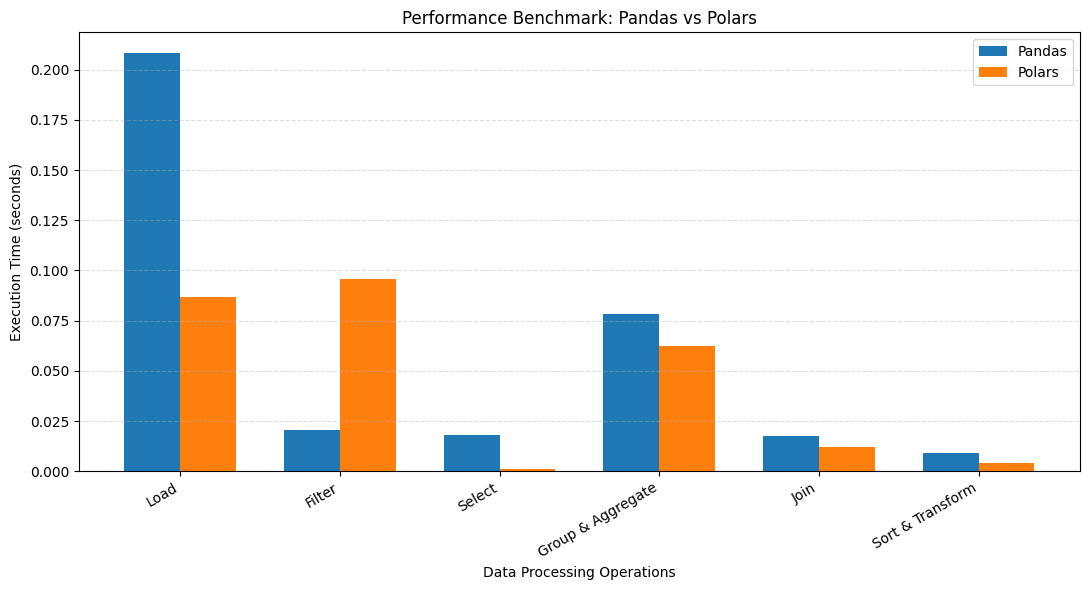

In [14]:
import matplotlib.pyplot as plt
import numpy as np

operations = performance_results["Operation"]
pandas_times = performance_results["Pandas (seconds)"]
polars_times = performance_results["Polars (seconds)"]

x = np.arange(len(operations))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(x - width/2, pandas_times, width, label="Pandas")
plt.bar(x + width/2, polars_times, width, label="Polars")

plt.xticks(x, operations, rotation=30, ha="right")
plt.ylabel("Execution Time (seconds)")
plt.xlabel("Data Processing Operations")
plt.title("Performance Benchmark: Pandas vs Polars")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

###Memory Benchmark

In [12]:
pandas_memory_mb = (
    pandas_df.memory_usage(index=True, deep=True).sum()
    / (1024 ** 2)
)

polars_memory_mb = polars_df.estimated_size("mb")

memory_results = pd.DataFrame({
    "Library": ["Pandas", "Polars"],
    "DataFrame Memory (MB)": [
        pandas_memory_mb, polars_memory_mb
    ]
})

display(memory_results.round(2))

print(f"Pandas memory: {pandas_memory_mb:.2f} MB")
print(f"Polars memory: {polars_memory_mb:.2f} MB")

,Library,DataFrame Memory (MB)
0,Pandas,39.91
1,Polars,11.90


Pandas memory: 39.91 MB
Polars memory: 11.90 MB


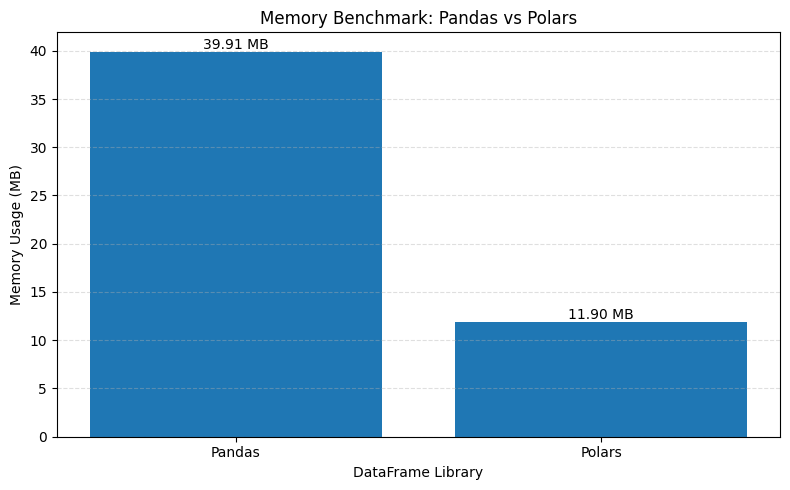

In [15]:
libraries = ["Pandas", "Polars"]
memory_usage = [pandas_memory_mb, polars_memory_mb]

plt.figure(figsize=(8, 5))

bars = plt.bar(libraries, memory_usage)

plt.ylabel("Memory Usage (MB)")
plt.xlabel("DataFrame Library")
plt.title("Memory Benchmark: Pandas vs Polars")

for bar, value in zip(bars, memory_usage):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.2f} MB",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

###Analysis and Conclusion:

The performance comparison between Pandas and Polars was conducted using the Online Retail dataset containing 150,000 transaction records. Both libraries were used to load, filter, select, group, aggregate, join, sort, and transform the data. Execution time and DataFrame memory usage were measured and visualized to compare their efficiency.

Observations: The performance visualization shows the execution time of Pandas and Polars for different data-processing operations, while the memory visualization compares the memory occupied by their DataFrames. The benchmark results help identify which library performs better for the selected dataset and operations.

Strengths and Limitations of Pandas: Pandas provides a simple and familiar interface, extensive data manipulation functions, and strong integration with Python's data science ecosystem. It is suitable for data cleaning, exploratory data analysis, statistical analysis, and small-to-medium-sized datasets. However, its memory consumption can increase significantly with large datasets, and many operations do not automatically use multiple CPU cores.

Strengths and Limitations of Polars: Polars uses a columnar data-processing engine and supports parallel execution and lazy query optimization. It can provide improved execution speed and memory efficiency for many data-processing workloads. However, its API and ecosystem may be less familiar to beginners, and some workflows may require adjustments when integrating with libraries designed primarily for Pandas.

Suitable Use Cases: Pandas is a good choice for exploratory data analysis, statistical workflows, and projects that depend on the wider Python data science ecosystem. Polars is a strong choice for larger data-processing pipelines, efficient transformations, and workloads that benefit from parallel execution and query optimization.

Final Conclusion: Both Pandas and Polars are useful Python libraries for data analysis. The most suitable choice depends on dataset size, processing requirements, memory constraints, and ecosystem compatibility. This experiment provided practical experience in data manipulation, benchmarking, memory analysis, and visualization, demonstrating how measured results can guide the selection of an appropriate data-processing library.